<a href="https://colab.research.google.com/github/jaustinjallah24/Duku-jallah-official/blob/main/Student_poerformance_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

np.random.seed(42)

data = {
    "Study_Hours": np.random.randint(1, 10, 500),
    "Attendance": np.random.randint(50, 101, 500),
    "Previous_Score": np.random.randint(40, 96, 500),
    "Assignments": np.random.randint(4, 11, 500)
}

df = pd.DataFrame(data)

performance_score = (
    df["Study_Hours"] * 6
    + df["Attendance"] * 0.35
    + df["Previous_Score"] * 0.45
    + df["Assignments"] * 2.5
)

df["Performance"] = np.where(
    performance_score >= 85,
    "Good",
    "Poor"
)

df.head()

,Study_Hours,Attendance,Previous_Score,Assignments,Performance
0,7,80,43,5,Good
1,4,68,61,4,Good
2,8,93,41,8,Good
3,5,88,49,5,Good
4,7,76,44,7,Good


In [ ]:
df.isnull().sum()

,0
Study_Hours,0
Attendance,0
Previous_Score,0
Assignments,0
Performance,0


In [ ]:
df.describe()

,Study_Hours,Attendance,Previous_Score,Assignments
count,500.000000,500.000000,500.000000,500.000000
mean,4.906000,74.830000,68.378000,6.950000
std,2.612051,14.940936,15.982302,1.980744
min,1.000000,50.000000,40.000000,4.000000
25%,3.000000,62.000000,56.000000,5.000000
50%,5.000000,75.000000,68.000000,7.000000
75%,7.000000,87.000000,82.000000,9.000000
max,9.000000,100.000000,95.000000,10.000000


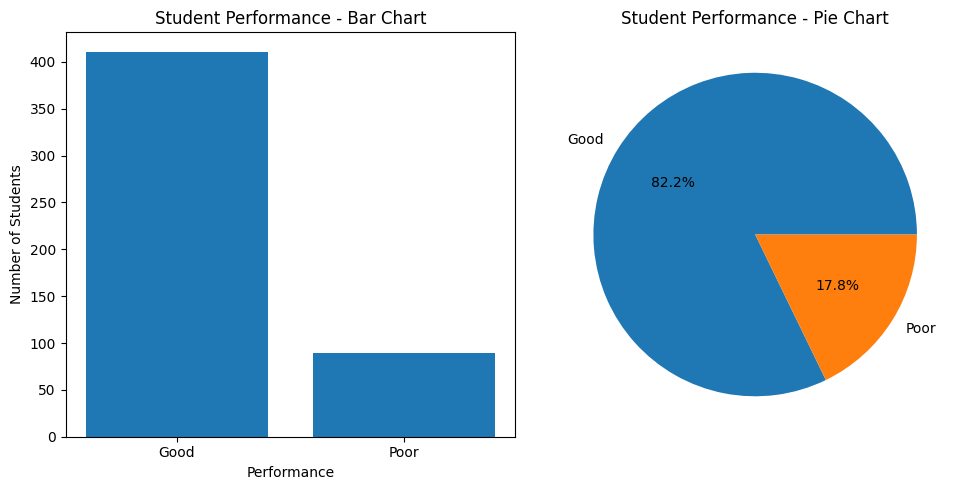

In [ ]:
import matplotlib.pyplot as plt

performance_counts = df["Performance"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Bar chart
axes[0].bar(
    performance_counts.index,
    performance_counts.values
)
axes[0].set_title("Student Performance - Bar Chart")
axes[0].set_xlabel("Performance")
axes[0].set_ylabel("Number of Students")

# Pie chart
axes[1].pie(
    performance_counts,
    labels=performance_counts.index,
    autopct="%1.1f%%"
)
axes[1].set_title("Student Performance - Pie Chart")

plt.tight_layout()
plt.show()

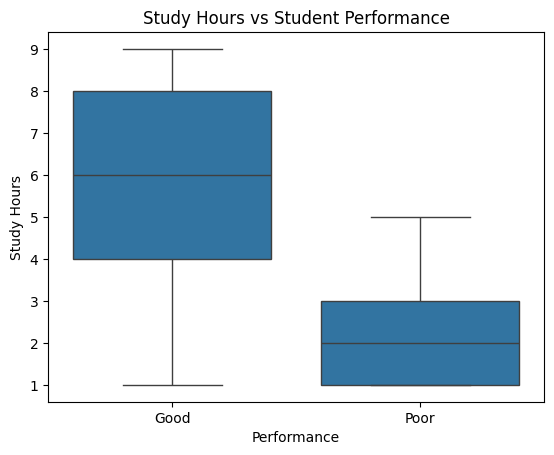

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(x="Performance", y="Study_Hours", data=df)

plt.title("Study Hours vs Student Performance")
plt.xlabel("Performance")
plt.ylabel("Study Hours")
plt.show()

In [ ]:
X = df[["Study_Hours", "Attendance", "Previous_Score", "Assignments"]]

X.head()

,Study_Hours,Attendance,Previous_Score,Assignments
0,7,80,43,5
1,4,68,61,4
2,8,93,41,8
3,5,88,49,5
4,7,76,44,7


In [ ]:
y = df["Performance"]

y.head()

,Performance
0,Good
1,Good
2,Good
3,Good
4,Good


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

In [ ]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (400, 4)
Testing data: (100, 4)


In [ ]:
from sklearn.metrics import accuracy_score

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 0.7
Accuracy Percentage: 70.0 %


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[11  2]
 [ 4  3]]


In [ ]:
print("Actual values:")
print(y_test.values)

print("\nPredicted values:")
print(y_pred)

Actual values:
['Good' 'Good' 'Poor' 'Good' 'Good' 'Poor' 'Good' 'Good' 'Poor' 'Good'
 'Good' 'Good' 'Poor' 'Good' 'Good' 'Good' 'Good' 'Poor' 'Poor' 'Poor']

Predicted values:
['Good' 'Good' 'Poor' 'Good' 'Good' 'Good' 'Poor' 'Good' 'Good' 'Good'
 'Good' 'Good' 'Poor' 'Poor' 'Good' 'Good' 'Good' 'Good' 'Good' 'Poor']


In [ ]:
model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=2,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Improved Model Accuracy:", accuracy)
print("Improved Accuracy Percentage:", accuracy * 100, "%")

Improved Model Accuracy: 0.7
Improved Accuracy Percentage: 70.0 %


In [ ]:
importance = model.feature_importances_

for feature, value in zip(X.columns, importance):
    print(feature, ":", value)

Study_Hours : 0.5832396167445897
Attendance : 0.12691821555125754
Previous_Score : 0.18627478431601907
Assignments : 0.10356738338813366


In [ ]:
np.random.seed(42)

data = {
    "Study_Hours": np.random.randint(1, 10, 500),
    "Attendance": np.random.randint(50, 101, 500),
    "Previous_Score": np.random.randint(40, 96, 500),
    "Assignments": np.random.randint(4, 11, 500)
}

df = pd.DataFrame(data)

performance_score = (
    df["Study_Hours"] * 6
    + df["Attendance"] * 0.35
    + df["Previous_Score"] * 0.45
    + df["Assignments"] * 2.5
)

df["Performance"] = np.where(
    performance_score >= 85,
    "Good",
    "Poor"
)

df.head()

,Study_Hours,Attendance,Previous_Score,Assignments,Performance
0,7,80,43,5,Good
1,4,68,61,4,Good
2,8,93,41,8,Good
3,5,88,49,5,Good
4,7,76,44,7,Good


In [ ]:
df.shape

(500, 5)

In [ ]:
X = df[["Study_Hours", "Attendance", "Previous_Score", "Assignments"]]

X.head()

,Study_Hours,Attendance,Previous_Score,Assignments
0,7,80,43,5
1,4,68,61,4
2,8,93,41,8
3,5,88,49,5
4,7,76,44,7


In [ ]:
y = df["Performance"]

y.head()

,Performance
0,Good
1,Good
2,Good
3,Good
4,Good


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (400, 4)
Testing data: (100, 4)


In [ ]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

In [ ]:
model.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

In [ ]:
y_pred = model.predict(X_test)

y_pred[:20]

array(['Good', 'Good', 'Good', 'Poor', 'Good', 'Poor', 'Good', 'Good',
       'Good', 'Good', 'Poor', 'Good', 'Good', 'Good', 'Good', 'Poor',
       'Good', 'Good', 'Good', 'Poor'], dtype=object)

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("New Model Accuracy:", accuracy)
print("New Accuracy Percentage:", accuracy * 100, "%")

New Model Accuracy: 0.95
New Accuracy Percentage: 95.0 %


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        Good       0.96      0.98      0.97        83
        Poor       0.88      0.82      0.85        17

    accuracy                           0.95       100
   macro avg       0.92      0.90      0.91       100
weighted avg       0.95      0.95      0.95       100



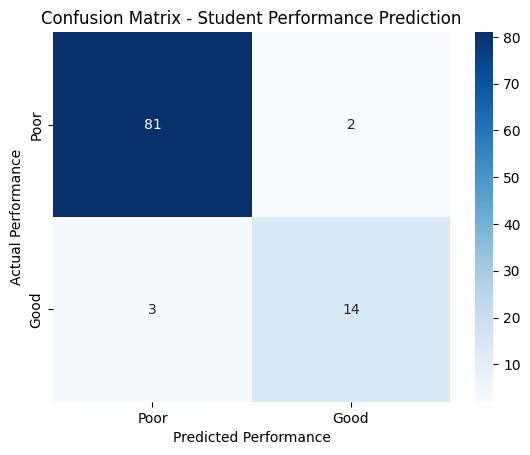

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Poor", "Good"],
    yticklabels=["Poor", "Good"]
)

plt.title("Confusion Matrix - Student Performance Prediction")
plt.xlabel("Predicted Performance")
plt.ylabel("Actual Performance")
plt.show()

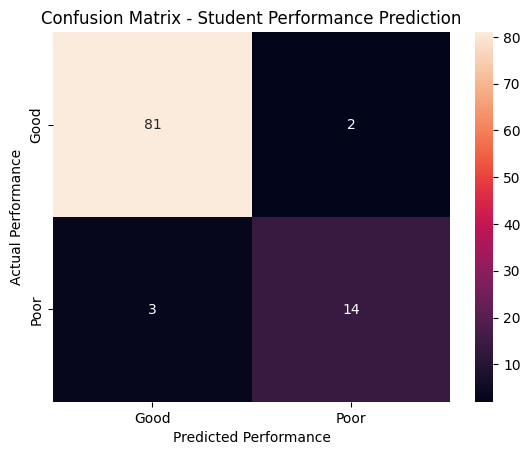

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=["Good", "Poor"])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Good", "Poor"],
    yticklabels=["Good", "Poor"]
)

plt.title("Confusion Matrix - Student Performance Prediction")
plt.xlabel("Predicted Performance")
plt.ylabel("Actual Performance")
plt.show()

In [ ]:
importance = model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
0,Study_Hours,0.432824
2,Previous_Score,0.275176
1,Attendance,0.147626
3,Assignments,0.144373


In [ ]:
new_student = pd.DataFrame({
    "Study_Hours": [7],
    "Attendance": [92],
    "Previous_Score": [85],
    "Assignments": [9]
})

prediction = model.predict(new_student)

print("Predicted Performance:", prediction[0])

Predicted Performance: Good


In [ ]:
new_students = pd.DataFrame({
    "Study_Hours": [2, 4, 6, 8, 5],
    "Attendance": [55, 70, 85, 95, 80],
    "Previous_Score": [45, 60, 75, 90, 70],
    "Assignments": [5, 6, 8, 10, 7]
})

predictions = model.predict(new_students)

new_students["Predicted_Performance"] = predictions

new_students

,Study_Hours,Attendance,Previous_Score,Assignments,Predicted_Performance
0,2,55,45,5,Poor
1,4,70,60,6,Good
2,6,85,75,8,Good
3,8,95,90,10,Good
4,5,80,70,7,Good


In [ ]:
probabilities = model.predict_proba(new_students[
    ["Study_Hours", "Attendance", "Previous_Score", "Assignments"]
])

new_students["Probability_Good"] = probabilities[:, 0]
new_students["Probability_Poor"] = probabilities[:, 1]

new_students

,Study_Hours,Attendance,Previous_Score,Assignments,Predicted_Performance,Probability_Good,Probability_Poor
0,2,55,45,5,Poor,0.030,0.970
1,4,70,60,6,Good,0.985,0.015
2,6,85,75,8,Good,1.000,0.000
3,8,95,90,10,Good,1.000,0.000
4,5,80,70,7,Good,0.985,0.015


In [ ]:
print(model.classes_)

['Good' 'Poor']


In [ ]:
print(model.classes_)

['Good' 'Poor']


In [ ]:
probabilities = model.predict_proba(new_students[
    ["Study_Hours", "Attendance", "Previous_Score", "Assignments"]
])

new_students["Probability_Good"] = probabilities[:, 0]
new_students["Probability_Poor"] = probabilities[:, 1]

new_students

,Study_Hours,Attendance,Previous_Score,Assignments,Predicted_Performance,Probability_Good,Probability_Poor
0,2,55,45,5,Poor,0.030,0.970
1,4,70,60,6,Good,0.985,0.015
2,6,85,75,8,Good,1.000,0.000
3,8,95,90,10,Good,1.000,0.000
4,5,80,70,7,Good,0.985,0.015


In [ ]:
new_students["Probability_Good"] = (
    new_students["Probability_Good"] * 100
).round(2)

new_students["Probability_Poor"] = (
    new_students["Probability_Poor"] * 100
).round(2)

new_students

,Study_Hours,Attendance,Previous_Score,Assignments,Predicted_Performance,Probability_Good,Probability_Poor
0,2,55,45,5,Poor,3.0,97.0
1,4,70,60,6,Good,98.5,1.5
2,6,85,75,8,Good,100.0,0.0
3,8,95,90,10,Good,100.0,0.0
4,5,80,70,7,Good,98.5,1.5


In [ ]:
df.to_csv("student_performance_dataset.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [ ]:
from sklearn.metrics import accuracy_score

final_accuracy = accuracy_score(y_test, y_pred)

print("Final Model Accuracy:", final_accuracy)
print("Final Model Accuracy Percentage:", final_accuracy * 100, "%")

Final Model Accuracy: 0.95
Final Model Accuracy Percentage: 95.0 %


In [ ]:
import joblib

joblib.dump(model, "student_performance_model.pkl")

print("Model saved successfully!")

Model saved successfully!
